### Preparação para o SHAP

Primeiro, vamos carregar os dados e o modelo, e então calcular os valores SHAP necessários para a plotagem.

In [1]:
!pip install folium

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium

# Configuração de estilo
sns.set_theme(style="whitegrid")
%matplotlib inline

# Criando dados de exemplo para o projeto (COPIE ISSO)
data = {
    'Ano': [2018, 2019, 2020, 2021, 2022, 2018, 2019, 2020, 2021, 2022],
    'Vendas_Automoveis': [5000, 4800, 3000, 3500, 4000, 2000, 1800, 1000, 1200, 1500],
    'Gastos_Publicidade': [1000, 1100, 800, 900, 950, 500, 450, 300, 350, 400],
    'Tipo_Veiculo': ['Sedan', 'Sedan', 'Sedan', 'Sedan', 'Sedan', 'SUV', 'SUV', 'SUV', 'SUV', 'SUV'],
    'Recessao': [0, 0, 1, 1, 1, 0, 0, 1, 1, 1],
    'PIB': [2.0, 2.1, -1.0, -0.5, 1.0, 2.0, 2.1, -1.0, -0.5, 1.0],
    'Sazonalidade': [0.8, 0.9, 0.5, 0.6, 0.7, 0.8, 0.9, 0.5, 0.6, 0.7],
    'Preco_Medio': [50000, 51000, 49000, 52000, 53000, 70000, 71000, 69000, 72000, 73000],
    'Taxa_Desemprego': [5.0, 5.1, 12.0, 11.0, 9.0, 5.0, 5.1, 12.0, 11.0, 9.0]
}
df = pd.DataFrame(data)
df.head()

,Ano,Vendas_Automoveis,Gastos_Publicidade,Tipo_Veiculo,Recessao,PIB,Sazonalidade,Preco_Medio,Taxa_Desemprego
0,2018,5000,1000,Sedan,0,2.0,0.8,50000,5.0
1,2019,4800,1100,Sedan,0,2.1,0.9,51000,5.1
2,2020,3000,800,Sedan,1,-1.0,0.5,49000,12.0
3,2021,3500,900,Sedan,1,-0.5,0.6,52000,11.0
4,2022,4000,950,Sedan,1,1.0,0.7,53000,9.0


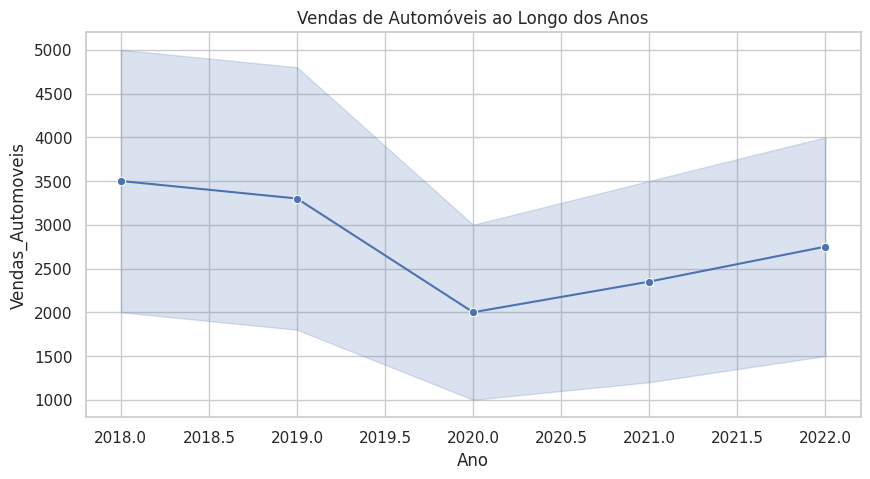

In [3]:
plt.figure(figsize=(10, 5))
sns.lineplot(data=df, x='Ano', y='Vendas_Automoveis', marker='o')
plt.title('Vendas de Automóveis ao Longo dos Anos')
plt.show()

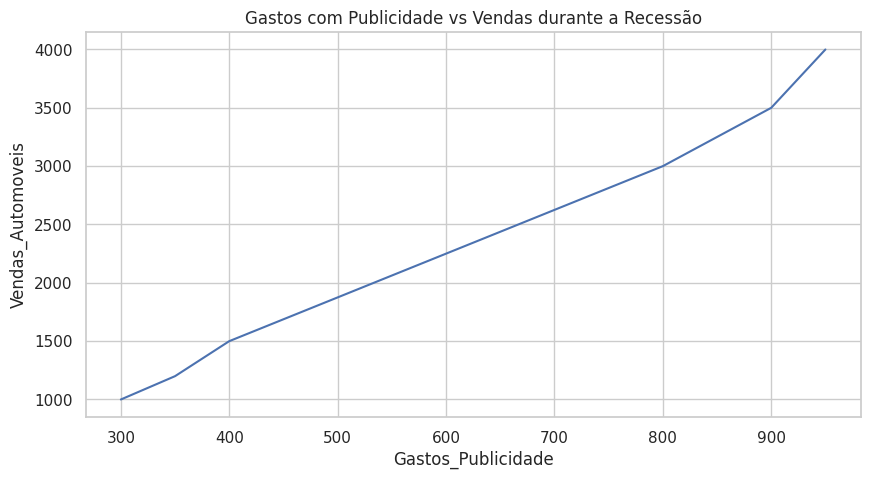

In [4]:
plt.figure(figsize=(10, 5))
df_rec = df[df['Recessao'] == 1]
sns.lineplot(data=df_rec, x='Gastos_Publicidade', y='Vendas_Automoveis')
plt.title('Gastos com Publicidade vs Vendas durante a Recessão')
plt.show()

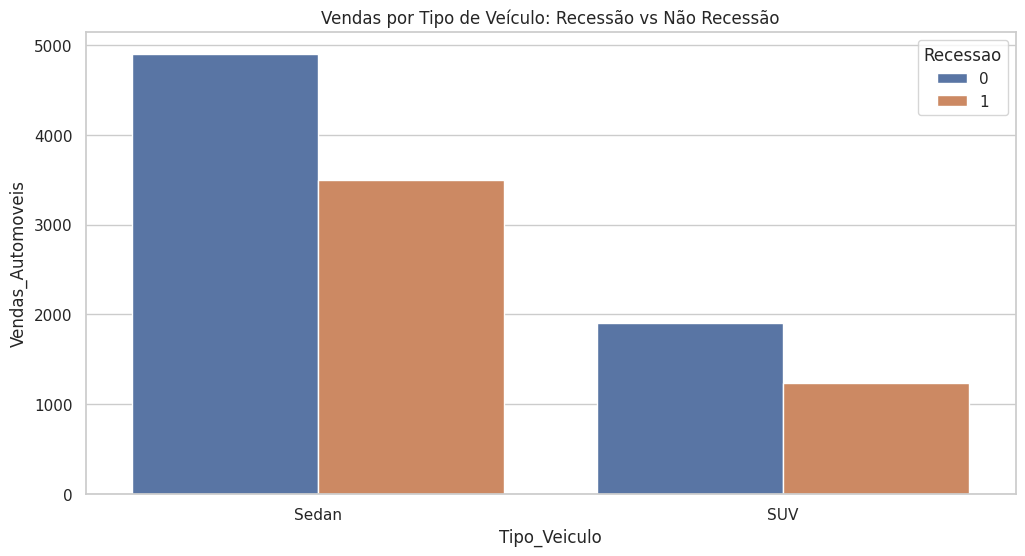

In [5]:
plt.figure(figsize=(12, 6))
sns.barplot(data=df, x='Tipo_Veiculo', y='Vendas_Automoveis', hue='Recessao', errorbar=None)
plt.title('Vendas por Tipo de Veículo: Recessão vs Não Recessão')
plt.show()

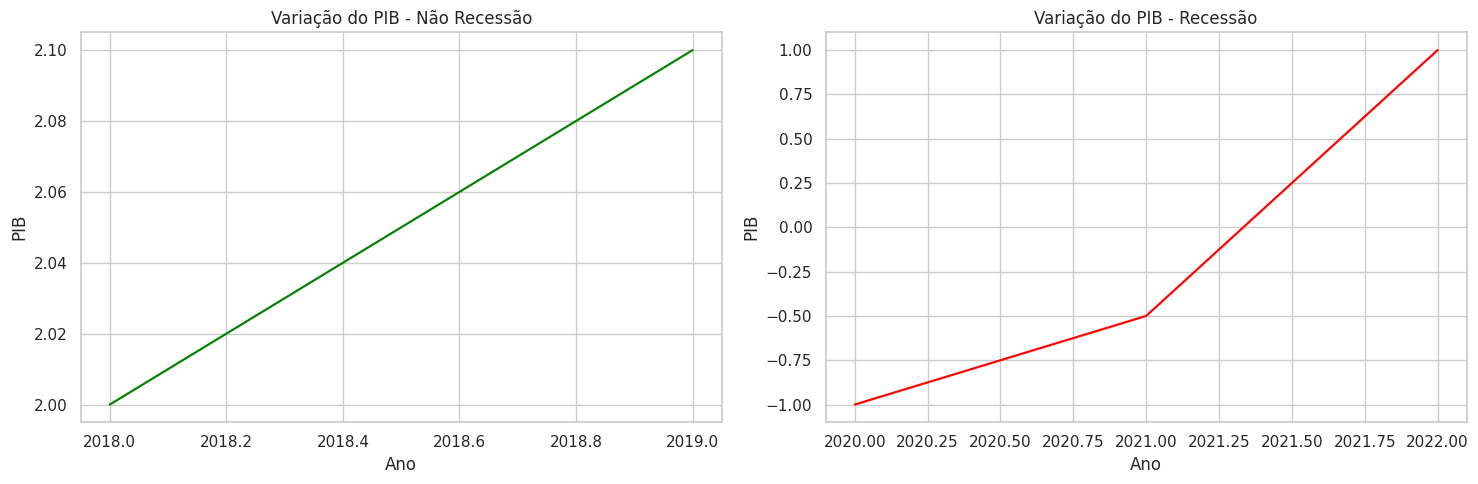

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.lineplot(ax=axes[0], data=df[df['Recessao'] == 0], x='Ano', y='PIB', color='green')
axes[0].set_title('Variação do PIB - Não Recessão')
sns.lineplot(ax=axes[1], data=df[df['Recessao'] == 1], x='Ano', y='PIB', color='red')
axes[1].set_title('Variação do PIB - Recessão')
plt.tight_layout()
plt.show()

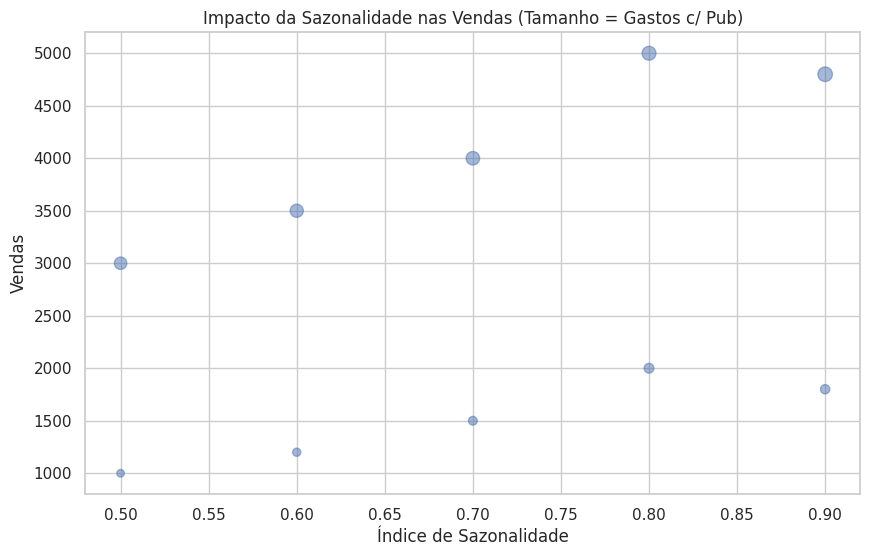

In [7]:
plt.figure(figsize=(10, 6))
plt.scatter(df['Sazonalidade'], df['Vendas_Automoveis'], s=df['Gastos_Publicidade']/10, alpha=0.5)
plt.title('Impacto da Sazonalidade nas Vendas (Tamanho = Gastos c/ Pub)')
plt.xlabel('Índice de Sazonalidade')
plt.ylabel('Vendas')
plt.show()

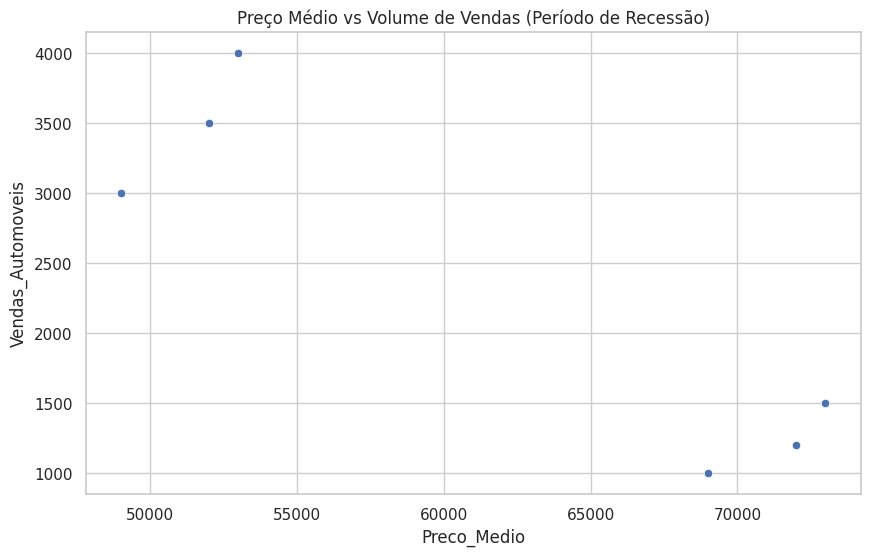

In [8]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df[df['Recessao'] == 1], x='Preco_Medio', y='Vendas_Automoveis')
plt.title('Preço Médio vs Volume de Vendas (Período de Recessão)')
plt.show()

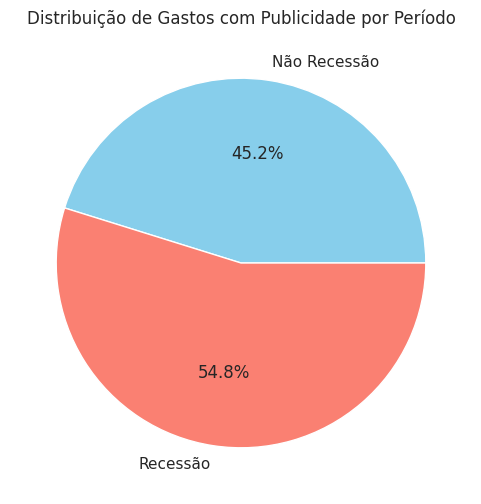

In [9]:
gastos_por_periodo = df.groupby('Recessao')['Gastos_Publicidade'].sum()
plt.figure(figsize=(6, 6))
plt.pie(gastos_por_periodo, labels=['Não Recessão', 'Recessão'], autopct='%1.1f%%', colors=['skyblue', 'salmon'])
plt.title('Distribuição de Gastos com Publicidade por Período')
plt.show()

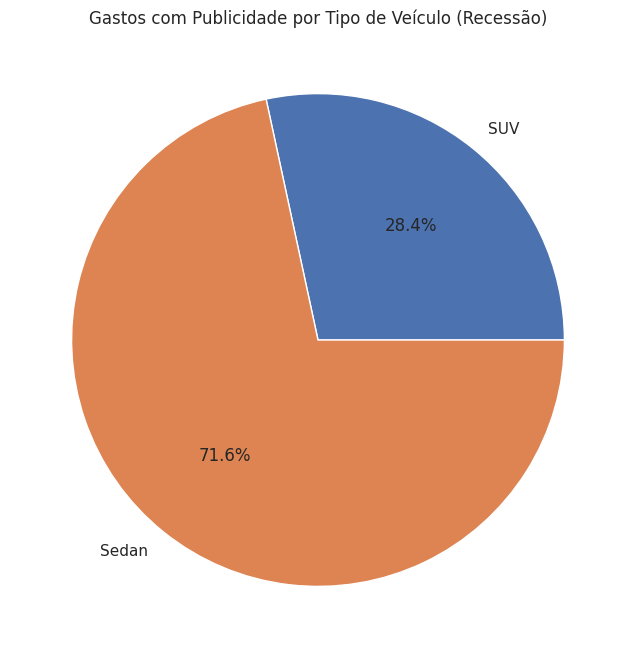

In [10]:
df_rec = df[df['Recessao'] == 1]
gastos_veiculo = df_rec.groupby('Tipo_Veiculo')['Gastos_Publicidade'].sum()
plt.figure(figsize=(8, 8))
plt.pie(gastos_veiculo, labels=gastos_veiculo.index, autopct='%1.1f%%')
plt.title('Gastos com Publicidade por Tipo de Veículo (Recessão)')
plt.show()

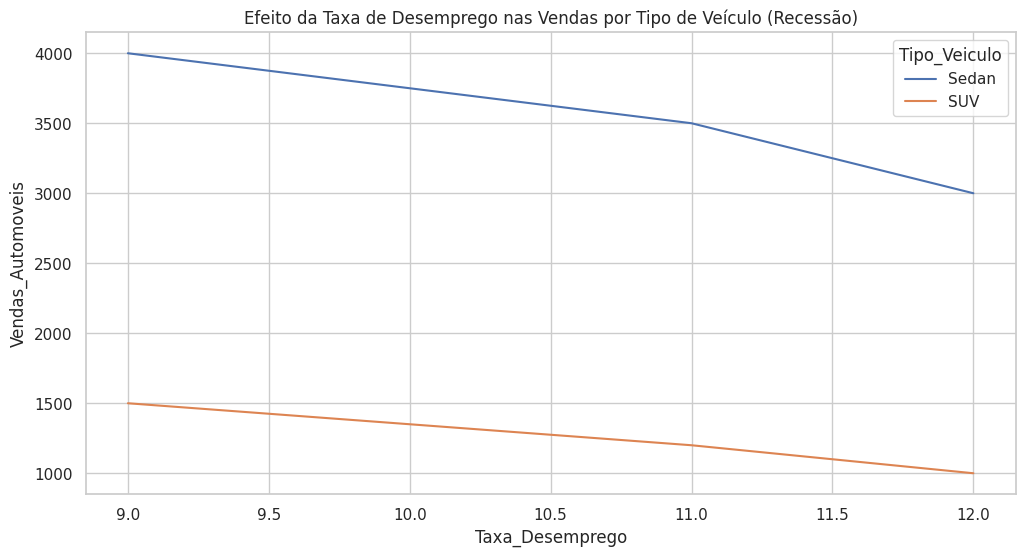

In [11]:
plt.figure(figsize=(12, 6))
sns.lineplot(data=df_rec, x='Taxa_Desemprego', y='Vendas_Automoveis', hue='Tipo_Veiculo')
plt.title('Efeito da Taxa de Desemprego nas Vendas por Tipo de Veículo (Recessão)')
plt.show()